# Phân Loại Cột Dữ Liệu Telco Churn

* **Tài chính & Giá trị:** `MonthlyCharges` (cước tháng), `TotalCharges` (tổng cước).
* **Dịch vụ & Gắn kết:** `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.
* **Giai đoạn Khách hàng:** `tenure` (số tháng gắn bó).
* **Rủi ro Thanh toán & Hợp đồng:** `Contract` (loại hợp đồng), `PaperlessBilling` (hóa đơn điện tử), `PaymentMethod` (phương thức thanh toán).
* **Nhân khẩu học & Gia đình:** `gender`, `SeniorCitizen` (người cao tuổi), `Partner` (bạn đời), `Dependents` (người phụ thuộc).
* **Định danh & Biến mục tiêu:** `customerID` (mã KH - bỏ khỏi mô hình), `Churn` (nhãn dự đoán).

## Mục tiêu
Tạo 14 đặc trưng mới từ dữ liệu gốc, nhóm hóa theo 5 nhóm ý nghĩa, rồi **kiểm chứng bằng % churn** để xem đặc trưng nào thực sự hữu ích.

Mỗi nhóm có 1 cell Markdown giải thích **vì sao tạo** + 1 cell code.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/cleaned/cleaned_telco_churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

# Hàm tính % churn theo 1 cột (dùng cho phần phân tích)
def pct_churn(col):
    return (df[df['Churn'] == 'Yes'].groupby(col).size() / df.groupby(col).size() * 100).round(1)

## Nhóm 1 - Tài chính & Giá trị

- **AverageMonthlyCharges** (phí TB 1 tháng thực tế) = `TotalCharges / tenure`. So sánh với `MonthlyCharges` hiện tại: nếu hiện tại cao hơn hẳn → khách vừa bị tăng giá / hết ưu đãi → dễ sốc giá mà rời đi.
- **ChargeRatio** (tỷ lệ tăng cước) = `MonthlyCharges / AverageMonthlyCharges`. > 1 nghĩa là đang trả nhiều hơn quá khứ.
- **LifetimeValue_Proxy** (giá trị vòng đời) = `MonthlyCharges * tenure`. Phân loại khách giá trị cao/thấp → quyết định có nên tốn chi phí giữ chân không.

In [13]:
# tenure = 0 (khách mới) thì phí TB = phí hiện tại
df['AverageMonthlyCharges'] = np.where(df['tenure'] > 0,
                                       df['TotalCharges'] / df['tenure'],
                                       df['MonthlyCharges'])
df['ChargeRatio'] = (df['MonthlyCharges'] / df['AverageMonthlyCharges']).round(2)
df['LifetimeValue_Proxy'] = df['MonthlyCharges'] * df['tenure']

df[['AverageMonthlyCharges', 'ChargeRatio', 'LifetimeValue_Proxy']].describe().round(2)

,AverageMonthlyCharges,ChargeRatio,LifetimeValue_Proxy
count,7032.00,7032.00,7032.00
mean,64.80,1.00,2283.15
std,30.19,0.05,2264.70
min,13.78,0.64,18.80
25%,36.18,0.98,397.80
50%,70.37,1.00,1394.57
75%,90.18,1.02,3791.25
max,121.40,1.45,8550.00


## Nhóm 2 - Sử dụng & Mức độ gắn kết dịch vụ

- **TotalServicesCount** = đếm số dịch vụ "Yes" trong 6 dịch vụ phụ. Dùng càng nhiều thì chi phí chuyển mạng càng cao → ít rời đi.
- **HasSecuritySuite** = 1 nếu có ≥2 trong {OnlineSecurity, DeviceProtection, TechSupport}. Nhóm "an tâm - kỹ thuật" thường trung thành hơn.
- **HasStreamingSuite** = 1 nếu có cả StreamingTV lẫn StreamingMovies. Nhóm giải trí cao rất nhạy với tốc độ mạng và cước phí.

In [14]:
serv6 = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
         'TechSupport', 'StreamingTV', 'StreamingMovies']
sec3 = ['OnlineSecurity', 'DeviceProtection', 'TechSupport']

df['TotalServicesCount'] = (df[serv6] == 'Yes').sum(axis=1)
df['HasSecuritySuite'] = ((df[sec3] == 'Yes').sum(axis=1) >= 2).astype(int)
df['HasStreamingSuite'] = ((df['StreamingTV'] == 'Yes') &
                           (df['StreamingMovies'] == 'Yes')).astype(int)

print(df['TotalServicesCount'].value_counts().sort_index())
print('HasSecuritySuite:', dict(df['HasSecuritySuite'].value_counts()))
print('HasStreamingSuite:', dict(df['HasStreamingSuite'].value_counts()))

TotalServicesCount
0    2213
1     966
2    1033
3    1117
4     850
5     569
6     284
Name: count, dtype: int64
HasSecuritySuite: {0: np.int64(5044), 1: np.int64(1988)}
HasStreamingSuite: {0: np.int64(5093), 1: np.int64(1939)}


## Nhóm 3 - Phân đoạn & Giai đoạn khách hàng

- **TenureGroup** = chia tenure thành 4 nhóm (0-12, 12-24, 24-48, >48 tháng). Churn tập trung ở những tháng đầu → mô hình bắt điểm gãy dễ hơn khi đã nhóm hóa.
- **IsNewCustomer** = 1 nếu `tenure ≤ 6` (giai đoạn onboarding dễ mất khách).
- **Contract_Tenure_Ratio** = tỷ lệ hợp đồng đã hoàn thành = `tenure / Contract_months` (Month-to-month=0 → đặt 1.0; One year=12; Two year=24, chặn tối đa 1.0).
- **IsNearContractEnd** = 1 nếu còn ≤2 tháng nữa là hết hạn hợp đồng → nguy cơ rời đột biến lúc gia hạn.

In [15]:
df['TenureGroup'] = pd.cut(df['tenure'], bins=[0, 12, 24, 48, 100],
                            labels=['0-12', '12-24', '24-48', '>48'],
                            include_lowest=True)
df['IsNewCustomer'] = (df['tenure'] <= 6).astype(int)

contract_months = {'Month-to-month': 0, 'One year': 12, 'Two year': 24}
cm = df['Contract'].map(contract_months)
df['Contract_Tenure_Ratio'] = np.where(cm > 0,
                                       (df['tenure'] / cm).clip(upper=1), 1.0)
df['IsNearContractEnd'] = ((cm > 0) & (df['tenure'] >= cm - 2)).astype(int)

print(df['TenureGroup'].value_counts().sort_index())
print('IsNewCustomer:', df['IsNewCustomer'].sum())
print('IsNearContractEnd:', df['IsNearContractEnd'].sum())

TenureGroup
0-12     2175
12-24    1024
24-48    1594
>48      2239
Name: count, dtype: int64
IsNewCustomer: 1470
IsNearContractEnd: 2969


## Nhóm 4 - Rủi ro thanh toán & hợp đồng

- **IsHighRiskPayment** = 1 nếu vừa dùng Electronic check vừa hợp đồng Month-to-month. Cặp kết hợp này có tỷ lệ churn cao vượt trội trong dữ liệu Telco.
- **IsAutomaticPayment** = 1 nếu PaymentMethod chứa "automatic". Thanh toán tự động → ít để ý cước → ít chủ động hủy.

In [16]:
df['IsHighRiskPayment'] = ((df['PaymentMethod'] == 'Electronic check') &
                           (df['Contract'] == 'Month-to-month')).astype(int)
df['IsAutomaticPayment'] = df['PaymentMethod'].str.contains('automatic').astype(int)

print('% churn - IsHighRiskPayment:')
print(pct_churn('IsHighRiskPayment'))
print('% churn - IsAutomaticPayment:')
print(pct_churn('IsAutomaticPayment'))

% churn - IsHighRiskPayment:
IsHighRiskPayment
0    16.9
1    53.7
dtype: float64
% churn - IsAutomaticPayment:
IsAutomaticPayment
0    34.7
1    16.0
dtype: float64


## Nhóm 5 - Nhân khẩu học & gia đình

- **HouseholdSize_Proxy** = (Partner=Yes) + (Dependents=Yes). Hộ có bạn đời/người phụ thuộc → ổn định, ít đổi mạng.
- **IsSingleSenior** = 1 nếu cao tuổi + sống độc thân (không Partner, không Dependents) → nhóm có nhu cầu hỗ trợ riêng.

In [17]:
df['HouseholdSize_Proxy'] = (df['Partner'] == 'Yes').astype(int) + (df['Dependents'] == 'Yes').astype(int)
df['IsSingleSenior'] = ((df['SeniorCitizen'] == 1) &
                        (df['Partner'] == 'No') &
                        (df['Dependents'] == 'No')).astype(int)

print(df['HouseholdSize_Proxy'].value_counts().sort_index())
print('IsSingleSenior:', df['IsSingleSenior'].sum())

HouseholdSize_Proxy
0    3280
1    2012
2    1740
Name: count, dtype: int64
IsSingleSenior: 561


## Phân tích: kiểm chứng đặc trưng mới bằng % churn

Nếu % churn 2 nhóm (0 và 1) **khác nhau nhiều** → đặc trưng hữu ích. Đường reference: 26.5% (chung toàn bộ dữ liệu).

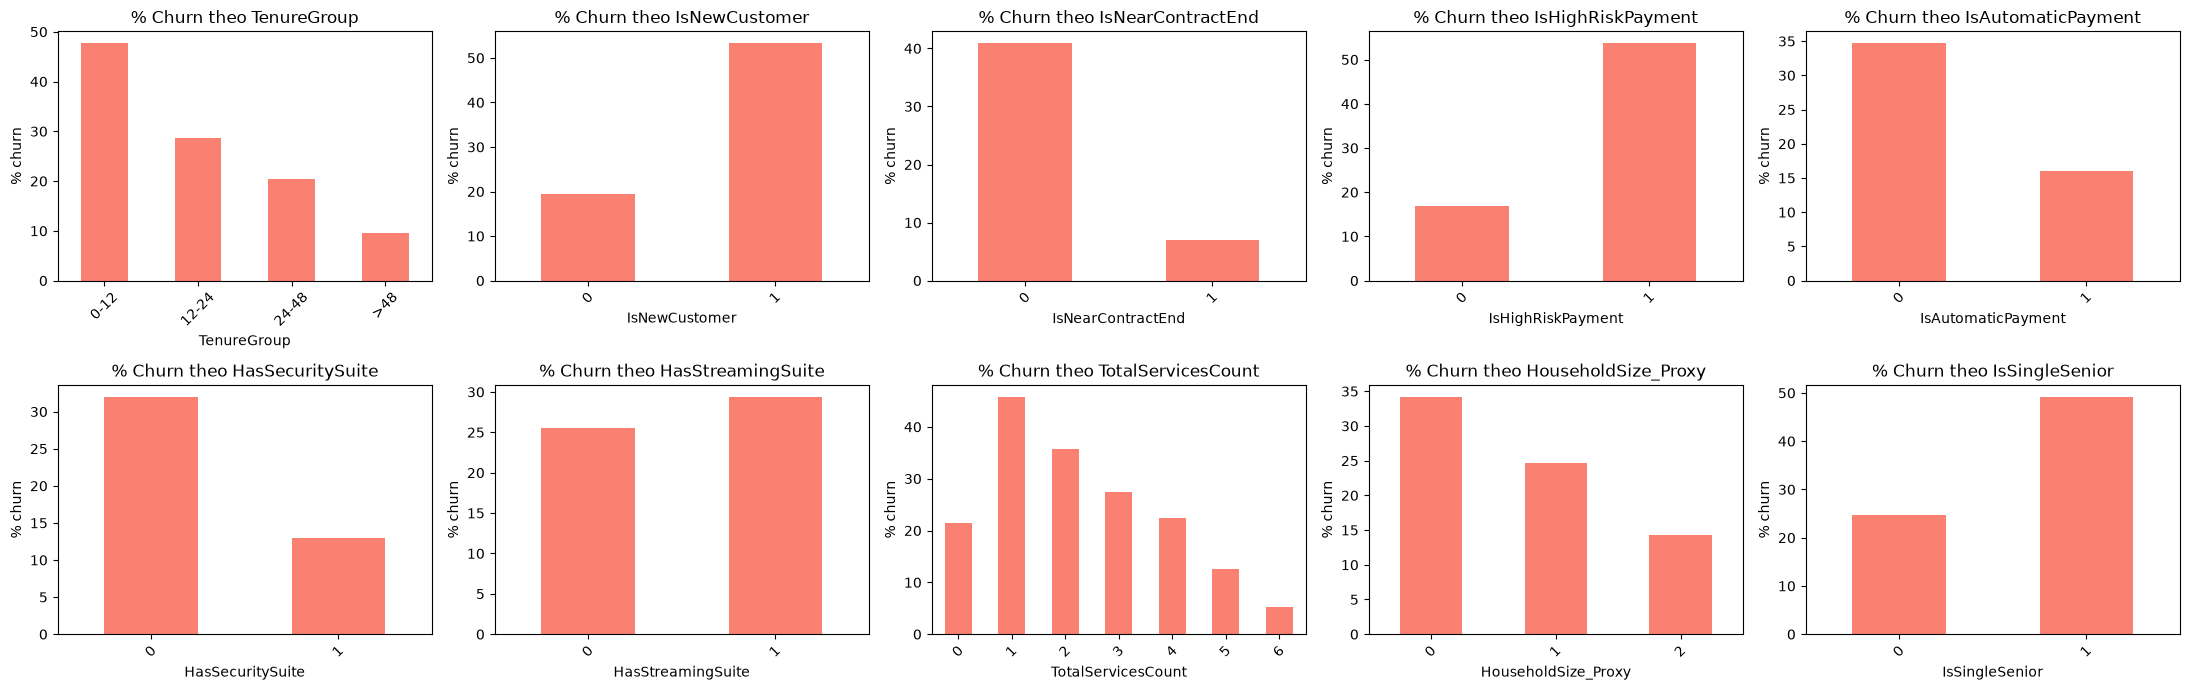

In [18]:
check_cols = ['TenureGroup', 'IsNewCustomer', 'IsNearContractEnd',
              'IsHighRiskPayment', 'IsAutomaticPayment',
              'HasSecuritySuite', 'HasStreamingSuite', 'TotalServicesCount',
              'HouseholdSize_Proxy', 'IsSingleSenior']

fig, axes = plt.subplots(2, 5, figsize=(22, 7))
for ax, col in zip(axes.flat, check_cols):
    pct_churn(col).plot(kind='bar', ax=ax, color='salmon')
    ax.set_title(f'% Churn theo {col}')
    ax.set_ylabel('% churn')
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

In [19]:
# So sánh giá trị trung bình của đặc trưng số giữa 2 nhóm Churn / Ở lại
num_feats = ['AverageMonthlyCharges', 'ChargeRatio', 'LifetimeValue_Proxy',
             'TotalServicesCount', 'Contract_Tenure_Ratio']

rows = []
for c in num_feats:
    rows.append({'Đặc trưng': c,
                 'TB (ở lại)': df[df['Churn'] == 'No'][c].mean(),
                 'TB (churn)': df[df['Churn'] == 'Yes'][c].mean()})
pd.DataFrame(rows).round(2)

,Đặc trưng,TB (ở lại),TB (churn)
0,AverageMonthlyCharges,61.31,74.43
1,ChargeRatio,1.00,1.00
2,LifetimeValue_Proxy,2555.20,1531.61
3,TotalServicesCount,2.14,1.77
4,Contract_Tenure_Ratio,0.98,1.00


## Kết luận

- Đã tạo **14 đặc trưng mới** thuộc 5 nhóm (xem phần đầu notebook).
- Biểu đồ % churn cho thấy các đặc trưng nhóm rủi ro (thanh toán, hợp đồng) và giai đoạn (tenure mới) phân biệt khách rời/ở **rõ nhất**.
- Toàn bộ dữ liệu + đặc trưng mới được lưu xuống `data/processed/df_features.csv` cho notebook 04 (mã hóa) sử dụng.

In [ ]:
import os
os.makedirs('../data/feature_data', exist_ok=True)
df.to_csv('../data/feature_data/df_features.csv', index=False)
print('Đã lưu. Số dòng, cột:', df.shape)

Đã lưu. Số dòng, cột: (7032, 35)
